# ROC-AUC & Learning Curves — Deep Dive

**Goal:** Master ROC-AUC — what it actually measures, when it lies, and how to use it correctly. Then learn how learning curves guide data-collection decisions.

**Why it matters:**
- ROC-AUC is the most-cited metric in ML papers and competitions.
- But it has **hidden biases** that mislead on heavily imbalanced data.
- Learning curves answer the critical question: "Do I need more data, or a better model?"

**Prerequisite:** [02-confusion-metrics.ipynb](./02-confusion-metrics.ipynb)

**Datasets:** Titanic + synthetic imbalanced data

---

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, cross_val_score, learning_curve,
    StratifiedKFold, validation_curve,
)
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    roc_curve, roc_auc_score, precision_recall_curve, average_precision_score,
    accuracy_score, f1_score, classification_report,
)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
np.random.seed(42)

print("Setup complete.")



Setup complete.


## What ROC-AUC Actually Measures

**ROC = Receiver Operating Characteristic.**

For every threshold, we compute:
- **TPR (True Positive Rate)** = TP / (TP + FN) = Recall
- **FPR (False Positive Rate)** = FP / (FP + TN) = 1 − Specificity

The ROC curve plots TPR vs FPR as threshold sweeps from 1 → 0.

**AUC = Area Under the Curve.**

### The crucial interpretation

**AUC = probability that a randomly chosen positive sample is ranked higher than a randomly chosen negative sample.**

This is the *ranking* interpretation. AUC is threshold-independent — it evaluates the model's ability to *order* predictions correctly.

### Why AUC is nice
- Threshold-independent
- Invariant to class priors (mostly)
- Single number, easy to compare models

### Why AUC lies
- **Optimistic on heavily imbalanced data.** A large TN count inflates FPR stability, hiding weak positive detection.
- **Doesn't care about absolute probabilities.** A model that outputs 0.51 for positives and 0.49 for negatives gets AUC = 1.0 — but the probabilities are near-random.
- **Not aligned with business costs.** It weighs FP and FN equally.

**Rule of thumb:** Use ROC-AUC when classes are roughly balanced. Use **PR-AUC** when positives are rare (<10%).

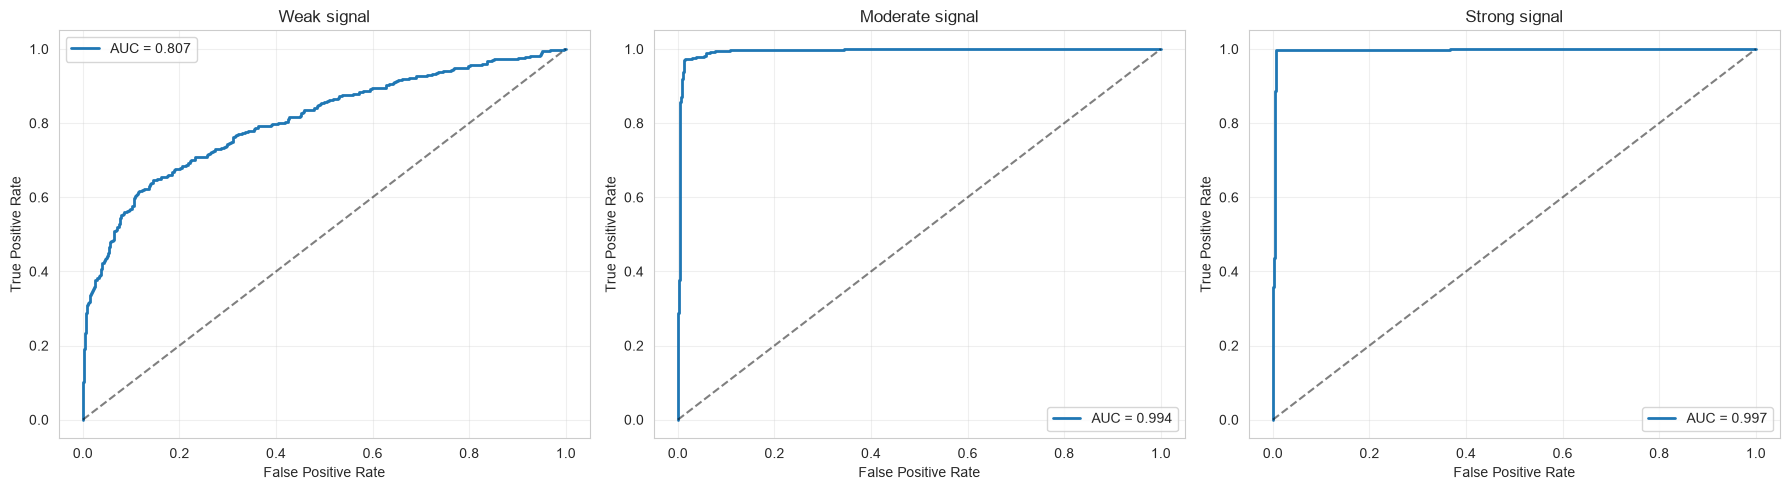

In [4]:
from sklearn.datasets import make_classification

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

configs = [
    (0.5, "Weak signal"),
    (1.5, "Moderate signal"),
    (3.0, "Strong signal"),
]

for ax, (sep, title) in zip(axes, configs):
  X_syn, y_syn = make_classification(
    n_samples=1000,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_clusters_per_class=1,
    class_sep=sep,
    flip_y=0.01,
    random_state=42,

  )
  clf = LogisticRegression(random_state=42).fit(X_syn, y_syn)
  proba = clf.predict_proba(X_syn)[:, 1]
  auc = roc_auc_score(y_syn, proba)
  fpr, tpr, _ = roc_curve(y_syn, proba)
  ax.plot(fpr, tpr, linewidth=2, label=f"AUC = {auc:.3f}")
  ax.plot([0, 1], [0, 1], "k--", alpha=0.5)
  ax.set_xlabel("False Positive Rate")
  ax.set_ylabel("True Positive Rate")
  ax.set_title(title)
  ax.legend()
  ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()





## ROC-AUC vs PR-AUC — When Each Lies

### ROC-AUC's problem on imbalance

ROC-AUC uses **FPR = FP / (FP + TN)**.  
When TN is huge (99% of data), even a large FP count yields a small FPR.

**Result:** the curve looks good even when the model has terrible precision.

### PR-AUC's advantage

PR-AUC uses **Precision = TP / (TP + FP)** and **Recall = TP / (TP + FN)**.  
It ignores TN entirely — which is exactly what we want when TN dominates.

**The baseline matters:**
- ROC baseline = 0.5 (always, regardless of imbalance)
- PR baseline = prevalence of positives (e.g., 0.01 for 1% positives)
- So PR-AUC = 0.3 on 1% positive data is *meaningful* — it's 30× better than random
- But ROC-AUC = 0.8 on the same data *sounds* better than it is

### Decision rule

| Positive rate | Metric |
|---------------|--------|
| ~50% | ROC-AUC or PR-AUC (they agree) |
| 10–30% | Either, report both |
| < 10% | **PR-AUC preferred** |
| < 1% | **PR-AUC mandatory** |

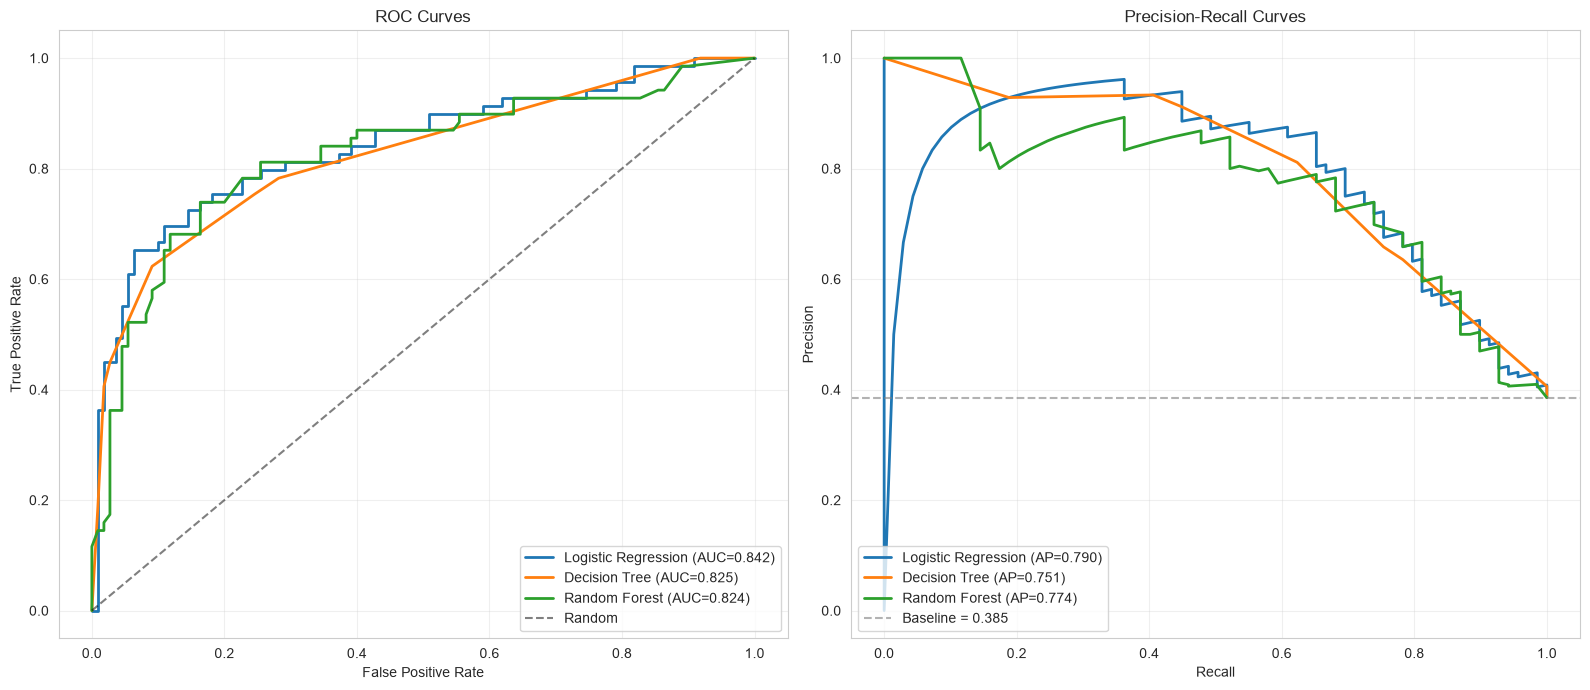

In [5]:
# Load & prep Titanic
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

df["HasCabin"] = df["Cabin"].notna().astype(int)
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)
df["Age"] = df.groupby(["Pclass", "Sex"])["Age"].transform(lambda x: x.fillna(x.median()))
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
df = df[["Survived", "Pclass", "Sex", "Age", "SibSp", "Parch",
         "Fare", "Embarked", "HasCabin", "FamilySize", "IsAlone"]]

X = df.drop(columns=["Survived"])
y = df["Survived"]

numeric_features = ["Age", "SibSp", "Parch", "Fare", "HasCabin", "FamilySize", "IsAlone"]
categorical_features = ["Pclass", "Sex", "Embarked"]

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), numeric_features),
    ("cat", Pipeline([
        ("imp", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore", drop="first")),
    ]), categorical_features),
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Compare 3 models
models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(max_iter=1000, random_state=42)),
    ]),
    "Decision Tree": Pipeline([
        ("preprocessor", preprocessor),
        ("model", DecisionTreeClassifier(max_depth=4, random_state=42)),
    ]),
    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)),
    ]),
}

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for name, model in models.items():
    model.fit(X_train, y_train)
    proba = model.predict_proba(X_test)[:, 1]

    # ROC
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    axes[0].plot(fpr, tpr, linewidth=2, label=f"{name} (AUC={auc:.3f})")

    # PR
    prec, rec, _ = precision_recall_curve(y_test, proba)
    ap = average_precision_score(y_test, proba)
    axes[1].plot(rec, prec, linewidth=2, label=f"{name} (AP={ap:.3f})")

# Style ROC
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5, label="Random")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curves")
axes[0].legend(loc="lower right")
axes[0].grid(True, alpha=0.3)

# Style PR
axes[1].axhline(y=y_test.mean(), color="gray", linestyle="--", alpha=0.6,
                label=f"Baseline = {y_test.mean():.3f}")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curves")
axes[1].legend(loc="lower left")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


**Three patterns and what to do:**

1. **Both curves plateau at high error** → **Underfitting.**
   - More data won't help.
   - Action: more features, more complex model, less regularization.

2. **Large gap, validation still dropping** → **Overfitting.**
   - More data WILL help.
   - Action: collect more data, regularize, simplify.

3. **Both curves converge at low error** → **Good fit.**
   - Action: nothing. Ship it.

### How to compute it in sklearn

`learning_curve(estimator, X, y, train_sizes=[...], cv=5)` returns:
- `train_sizes`: absolute sizes used
- `train_scores`: shape (n_sizes, n_folds)
- `val_scores`: shape (n_sizes, n_folds)

Average across folds to plot the mean; std for uncertainty bands.

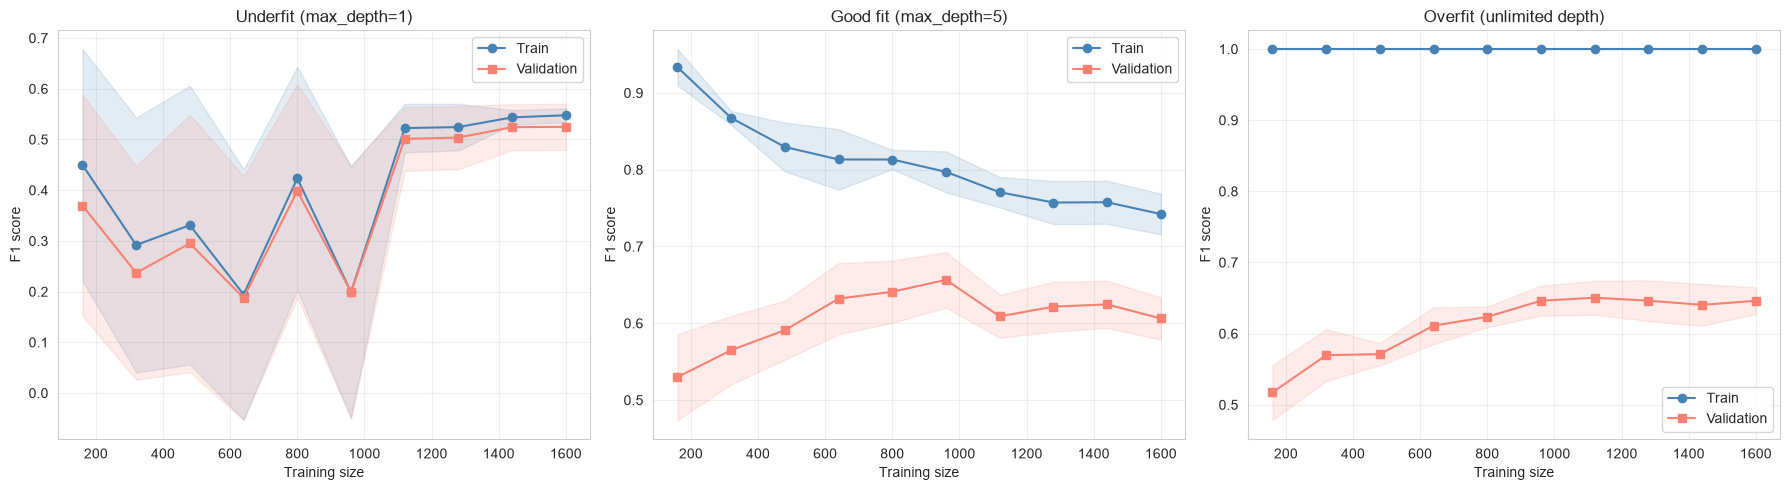

In [6]:
# Use synthetic data to compare under/good/overfit cases
from sklearn.datasets import make_classification

X_syn, y_syn = make_classification(
    n_samples=2000,
    n_features=20,
    n_informative=10,
    weights=[0.7, 0.3],
    flip_y=0.05,
    random_state=42,
)

def plot_lc(estimator, X, y, ax, title):
    """Compute and plot learning curve."""
    train_sizes, train_scores, val_scores = learning_curve(
        estimator, X, y,
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
        # StratifiedKFold → preserves class ratio in each fold.
        #   Use for classification with imbalanced data.
        #   For regression: KFold.
        
        train_sizes=np.linspace(0.1, 1.0, 10),
        scoring="f1",
        # "f1" → good general metric for classification.
        #   Alternatives: "accuracy", "roc_auc", "precision", "recall".
        #   sklearn always MAXIMIZES these (higher = better).
        
        n_jobs=-1,
        shuffle=True,
        random_state=42,
    )
    
    tm = train_scores.mean(axis=1)
    vm = val_scores.mean(axis=1)
    ts = train_scores.std(axis=1)
    vs = val_scores.std(axis=1)
    
    ax.plot(train_sizes, tm, "o-", color="steelblue", label="Train")
    ax.plot(train_sizes, vm, "s-", color="salmon",    label="Validation")
    ax.fill_between(train_sizes, tm - ts, tm + ts, alpha=0.15, color="steelblue")
    ax.fill_between(train_sizes, vm - vs, vm + vs, alpha=0.15, color="salmon")
    ax.set_xlabel("Training size")
    ax.set_ylabel("F1 score")
    ax.set_title(title)
    ax.legend()
    ax.grid(True, alpha=0.3)


fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Case 1: Underfit — shallow tree
plot_lc(
    DecisionTreeClassifier(max_depth=1, random_state=42),
    X_syn, y_syn, axes[0],
    "Underfit (max_depth=1)",
)

# Case 2: Good fit — moderate depth
plot_lc(
    DecisionTreeClassifier(max_depth=5, random_state=42),
    X_syn, y_syn, axes[1],
    "Good fit (max_depth=5)",
)

# Case 3: Overfit — unlimited depth
plot_lc(
    DecisionTreeClassifier(random_state=42),
    X_syn, y_syn, axes[2],
    "Overfit (unlimited depth)",
)

plt.tight_layout()
plt.show()

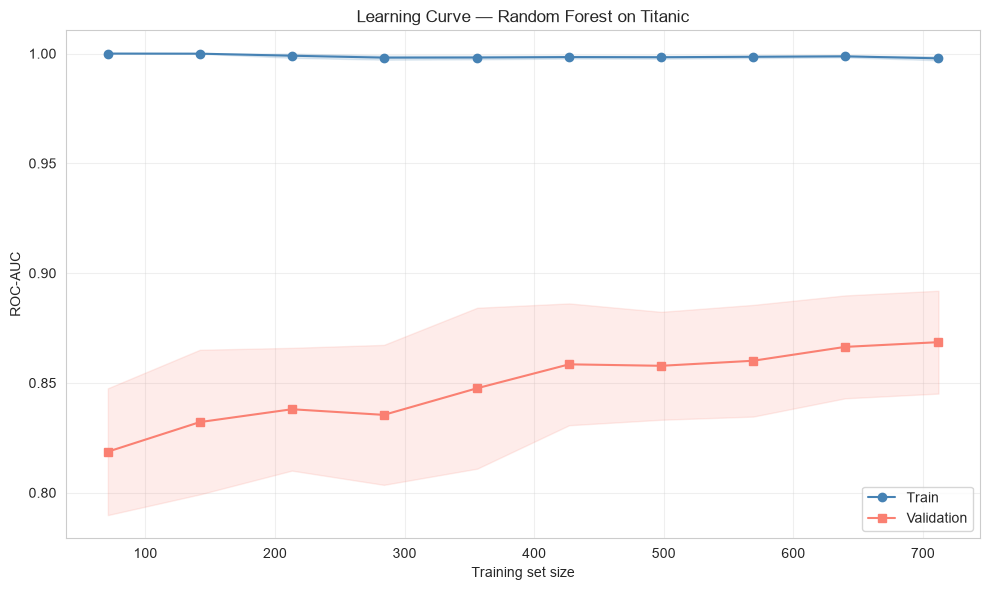

Final gap (train − validation): 0.1293
→ Overfit. More data or regularization would help.


In [7]:
# Real-world example on Titanic
rf_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)),
])

train_sizes, train_scores, val_scores = learning_curve(
    rf_pipe, X, y,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    train_sizes=np.linspace(0.1, 1.0, 10),
    scoring="roc_auc",
    n_jobs=-1,
)

tm, vm = train_scores.mean(axis=1), val_scores.mean(axis=1)
ts, vs = train_scores.std(axis=1), val_scores.std(axis=1)

plt.figure(figsize=(10, 6))
plt.plot(train_sizes, tm, "o-", color="steelblue", label="Train")
plt.plot(train_sizes, vm, "s-", color="salmon",    label="Validation")
plt.fill_between(train_sizes, tm - ts, tm + ts, alpha=0.15, color="steelblue")
plt.fill_between(train_sizes, vm - vs, vm + vs, alpha=0.15, color="salmon")
plt.xlabel("Training set size")
plt.ylabel("ROC-AUC")
plt.title("Learning Curve — Random Forest on Titanic")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Interpret
gap = tm[-1] - vm[-1]
print(f"Final gap (train − validation): {gap:.4f}")
if gap > 0.1:
    print("→ Overfit. More data or regularization would help.")
elif vm[-1] < 0.75:
    print("→ Underfit. Consider a richer model or better features.")
else:
    print("→ Balanced fit. Ship it.")

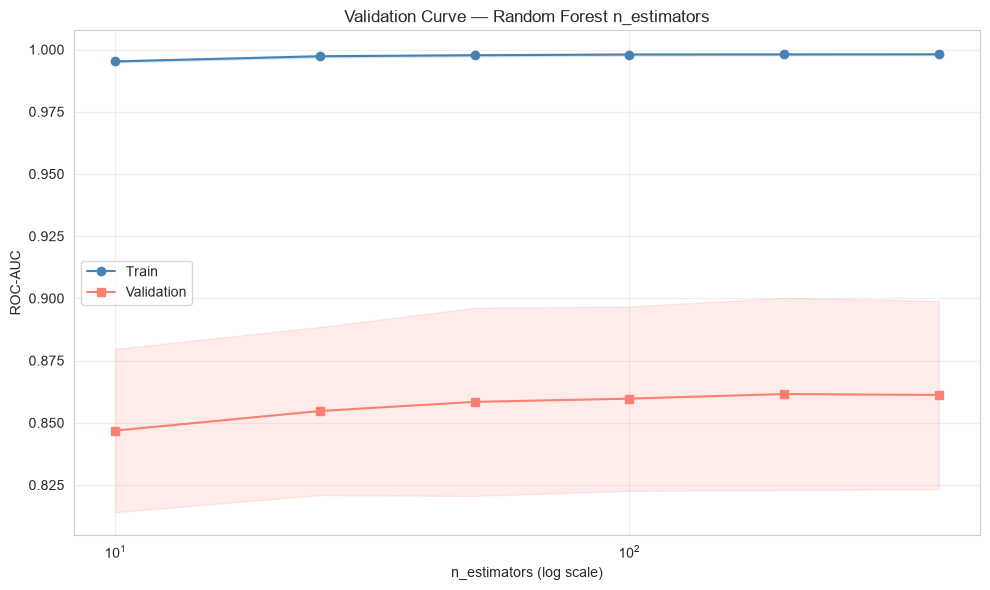

Best n_estimators by validation: 200


In [8]:
# Validation curve for RF's n_estimators
param_range = [10, 25, 50, 100, 200, 400]

train_scores, val_scores = validation_curve(
    Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(random_state=42, n_jobs=-1)),
    ]),
    X, y,
    param_name="model__n_estimators",
    # Must match the pipeline param name.
    # Same rule as GridSearchCV.
    
    param_range=param_range,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1,
)

tm, vm = train_scores.mean(axis=1), val_scores.mean(axis=1)
ts, vs = train_scores.std(axis=1), val_scores.std(axis=1)

plt.figure(figsize=(10, 6))
plt.plot(param_range, tm, "o-", color="steelblue", label="Train")
plt.plot(param_range, vm, "s-", color="salmon",    label="Validation")
plt.fill_between(param_range, tm - ts, tm + ts, alpha=0.15, color="steelblue")
plt.fill_between(param_range, vm - vs, vm + vs, alpha=0.15, color="salmon")
plt.xscale("log")
plt.xlabel("n_estimators (log scale)")
plt.ylabel("ROC-AUC")
plt.title("Validation Curve — Random Forest n_estimators")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

best_n = param_range[int(np.argmax(vm))]
print(f"Best n_estimators by validation: {best_n}")

## Learning Curve vs Validation Curve — Don't Confuse Them

| Aspect | Learning Curve | Validation Curve |
|--------|---------------|------------------|
| **X-axis** | Training set size | A hyperparameter value |
| **Answers** | Do I need more data? | What's the best hyperparameter? |
| **Fixed** | Model + hyperparameters | Model (hyperparameter varies) |
| **Output** | Error vs size | Error vs param |
| **Typical use** | Decide data-collection budget | Tune one hyperparameter |

**Real workflow:**
1. **Validation curve** → find good hyperparameters.
2. **Learning curve** → with the best hyperparameters, decide if more data helps.
3. **GridSearchCV** (next notebook) → automate step 1.

## 🚀 Next

→ [mini-project/compare-5-models.ipynb](./mini-project/compare-5-models.ipynb): put it all together.

Or skip ahead to:

→ [../06-deep-learning/01-nn-from-scratch.ipynb](../06-deep-learning/01-nn-from-scratch.ipynb) if the mini-project is optional for you.

In [9]:
import joblib

joblib.dump(preprocessor, "eval_preprocessor.joblib")
joblib.dump(models["Random Forest"], "rf_eval_titanic.joblib")
print("Saved: eval_preprocessor.joblib, rf_eval_titanic.joblib")

Saved: eval_preprocessor.joblib, rf_eval_titanic.joblib
